# 2 — The operational K-profile

Example 2 of the manuscript. The eddy viscosity of the Troen–Mahrt and
K-profile boundary-layer schemes,

$$K(z)=\kappa u_*\,z\,(1-z/h)^2,$$

is the cubic with a simple root at the surface and a double root at the
boundary-layer top. It is passed to `solve_poly_layers` coefficient-wise,
since the node-based LayerModel API does not include a cubic kind.

Two things need care, and both are physical. $K$ vanishes at both roots, so
the domain runs from the roughness length $z_0$ to just below $h$. And the
Taylor series on a layer converges inside the distance to the nearest root, so
the layer beside the double root must be thin compared with its distance from
it.

In [1]:
using Pkg
Pkg.activate(joinpath(@__DIR__, ".."))
using ELES, LinearAlgebra, Printf
ENV["GKSwstype"] = "100"
using Plots
default(frame = :box, grid = false, size = (820, 300),
        lw = 2, legendfontsize = 7, titlefontsize = 9, guidefontsize = 8)
include(joinpath(@__DIR__, "..", "examples", "reference_shooting.jl"))
println("layer kinds: ", LAYER_KINDS)

layer kinds: (:constant, :linear, :quadratic, :exponential)


  Activating project at `<package>`


In [2]:
kappa, ustar, h, f = 0.4, 0.3, 1000.0, 1.0e-4
z0, ztop = 0.1, 0.99h
k1 = kappa*ustar/h^2
coefficients = [0.0, k1*h*h, -2k1*h, k1]          # k1 z (z - h)^2 in powers of z
K(z) = coefficients[1] + coefficients[2]z + coefficients[3]z^2 + coefficients[4]z^3
z = collect(range(z0, ztop, length = 241))
@printf("peak %.2f m^2/s at z = h/3;  K(z0) = %.4f,  K(ztop) = %.4f\n",
        K(h/3), K(z0), K(ztop))
@printf("contrast %.0f:1 over %.2f Ekman depths\n",
        K(h/3)/K(ztop), (ztop - z0)/sqrt(2*K(h/3)/f))

peak 17.78 m^2/s at z = h/3;  K(z0) = 0.0120,  K(ztop) = 0.0119
contrast 1496:1 over 1.66 Ekman depths


## Choosing the partition

For a layer $[a,b]$ and a root $r$ of $K$, keeping $|x|\ge R$ in the local
coordinate requires $b\le a(R+1)/(R-1)$ when $r\le a$, and
$b\le(2r+a(R-1))/(R+1)$ when $r\ge b$. Taking the smaller bound over all
roots gives the widest admissible layer.

In [3]:
shift(mid, half) = [sum(coefficients[j+1]*binomial(j, i)*mid^(j-i)*half^i
                        for j in i:3) for i in 0:3]
build(e) = [shift((e[k] + e[k+1])/2, (e[k+1] - e[k])/2) for k in 1:length(e)-1]

function partition(R)
    e = [z0]
    while e[end] < ztop - 1e-9
        a = e[end]
        push!(e, min(a*(R + 1)/(R - 1), (2h + a*(R - 1))/(R + 1), ztop))
    end
    e
end

least_radius(e) = minimum(min(abs(-((e[k] + e[k+1])/2)/((e[k+1] - e[k])/2)),
                              abs((h - (e[k] + e[k+1])/2)/((e[k+1] - e[k])/2)))
                          for k in 1:length(e)-1)

reference = reference_arbitrary(K, 1im*f, -1.0im, 0.0im, z)
@printf("%-26s %5s %11s %11s %13s\n", "partition", "N", "min |x|", "tail", "vs RK4")
for (name, e) in ["uniform" => collect(range(z0, ztop, length = 17)),
                  "geometric to the wall" => z0 .* (ztop/z0) .^ range(0, 1, length = 17),
                  "root-respecting, R=1.5" => partition(1.5),
                  "root-respecting, R=3" => partition(3.0)]
    s = solve_poly_layers(e, build(e), 1im*f, -1.0im, 0.0im)
    @printf("%-26s %5d %11.3f %11.1e %13.2e\n", name, length(e) - 1,
            least_radius(e), series_tail(s),
            maximum(abs.(field(s, z) .- reference)))
end

partition                      N     min |x|        tail        vs RK4
uniform                       16       1.003     3.6e-03      1.40e-01
geometric to the wall         16       1.046     1.8e-03      2.38e-04
root-respecting, R=1.5         8       1.500     7.9e-28      7.65e-06
root-respecting, R=3          18       3.000     9.0e-75      7.65e-06


The first two partitions are unusable and `series_tail` says so
before any reference is consulted. Eight root-respecting layers suffice.

The remaining gap to the Runge–Kutta reference is the *reference's* error over
this 1496:1 contrast, not the solver's: the solver's answer is independent of
the truncation order and of which admissible partition is used.

In [4]:
e8, e18 = partition(1.5), partition(3.0)
s8 = solve_poly_layers(e8, build(e8), 1im*f, -1.0im, 0.0im)
s18 = solve_poly_layers(e18, build(e18), 1im*f, -1.0im, 0.0im)
@printf("order 160 versus 240            %.2e\n",
        maximum(abs.(field(s8, z) .-
                field(solve_poly_layers(e8, build(e8), 1im*f, -1.0im, 0.0im;
                                        order = 240), z))))
@printf("8 layers versus 18 layers       %.2e\n",
        maximum(abs.(field(s8, z) .- field(s18, z))))
for steps in (20000, 80000, 320000)
    @printf("RK4 with %7d steps          %.2e\n", steps,
            maximum(abs.(field(s8, z) .-
                    reference_arbitrary(K, 1im*f, -1.0im, 0.0im, z; steps))))
end

order 160 versus 240            0.00e+00
8 layers versus 18 layers       2.70e-14
RK4 with   20000 steps          7.65e-06
RK4 with   80000 steps          3.36e-08
RK4 with  320000 steps          1.32e-10


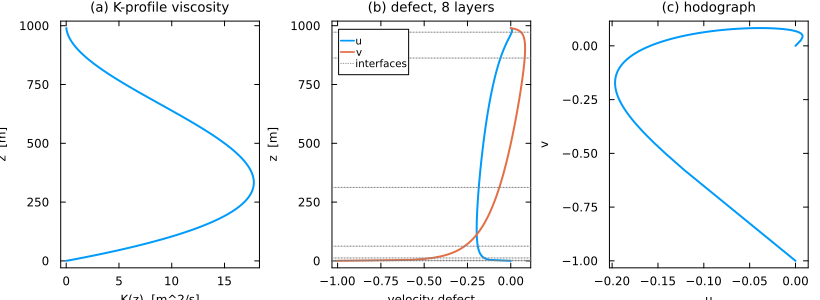

In [5]:
w = field(s8, z)
plot(
  plot(K.(z), z; xlabel = "K(z)  [m^2/s]", ylabel = "z  [m]", legend = false,
       title = "(a) K-profile viscosity"),
  begin
    p = plot(real.(w), z; label = "u", xlabel = "velocity defect",
             ylabel = "z  [m]", title = "(b) defect, 8 layers")
    plot!(p, imag.(w), z; label = "v")
    hline!(p, e8[2:end-1]; label = "interfaces", lc = :gray, ls = :dot, lw = 1)
  end,
  plot(real.(w), imag.(w); xlabel = "u", ylabel = "v", legend = false,
       title = "(c) hodograph");
  layout = (1, 3))